#Deep Learning para visión de computadoras
##Lab 3.3 GAN condicional, FID y aumento con datos sintéticos

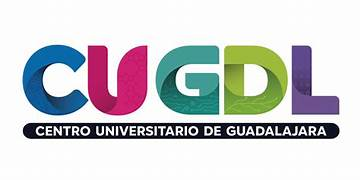

# Explica que es la aumentacion de datos coloca una imagen que lo ejemplifique y menciona cuales son las ventajas de aplicarlo en tu proyecto

[Aumento de datos con Ultralytics YOLO](https://docs.ultralytics.com/es/guides/yolo-data-augmentation)

El aumento de datos crea versiones modificadas de las imágenes de entrenamiento con espejo, desplazamiento o rotación sin cambiar su etiqueta, como muestra la figura de abajo con una misma imagen real. En mi proyecto con 50 imágenes reales por clase reduce el sobreajuste y mejora la generalización sin costo de etiquetado, y además es la línea base barata contra la que debe compararse la cGAN.

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.83MB/s]


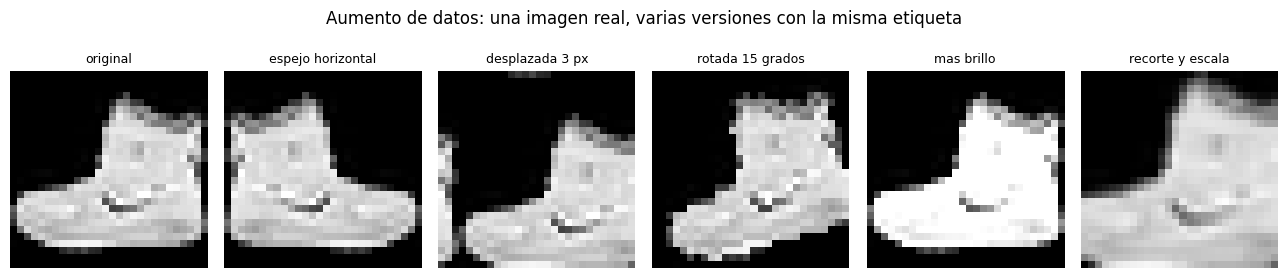

In [1]:
# Ejemplo de aumento de datos: una misma imagen real con distintas transformaciones (la etiqueta no cambia)
import numpy as np, matplotlib.pyplot as plt, torch
from torchvision import datasets
import torchvision.transforms.functional as TF

_ds = datasets.FashionMNIST("datos", train=True, download=True)
img = torch.as_tensor(np.asarray(_ds.data[0])).float().div(255).unsqueeze(0)   # (1, 28, 28) en [0, 1]
transformaciones = {
    "original": img,
    "espejo horizontal": img.flip(2),
    "desplazada 3 px": torch.roll(img, shifts=(3, 3), dims=(1, 2)),
    "rotada 15 grados": TF.rotate(img, 15),
    "mas brillo": (img * 1.3).clamp(0, 1),
    "recorte y escala": TF.resized_crop(img, 3, 3, 22, 22, [28, 28], antialias=True),
}
fig, ax = plt.subplots(1, len(transformaciones), figsize=(13, 2.6))
for a, (nombre, t) in zip(ax, transformaciones.items()):
    a.imshow(t[0], cmap="gray", vmin=0, vmax=1); a.set_title(nombre, fontsize=9); a.axis("off")
plt.suptitle("Aumento de datos: una imagen real, varias versiones con la misma etiqueta", y=1.05)
plt.tight_layout(); plt.savefig("aumento_ejemplo.png", dpi=110, bbox_inches="tight"); plt.show()

¿cGAN o aumento clásico? Datos sintéticos con pocos datos reales?
Si solo tengo 50 imágenes etiquetadas por clase, ¿vale la pena entrenar una GAN condicional para generar más datos, o basta con el aumento de datos clásico (volteos, rotaciones, traslaciones)?

Con las 60 000 imágenes de FashionMNIST cualquier CNN supera el 90 % y no se nota ninguna diferencia. Con 500 imágenes (50 por clase) el problema se vuelve real y medible.

Las tres reglas de un experimento honesto
Sin fuga: la cGAN solo ve las mismas 500 imágenes que el clasificador.
Mismo presupuesto: todos los clasificadores tienen la misma arquitectura y el mismo número de pasos de entrenamiento (no de épocas: con más imágenes habría más pasos y la comparación sería injusta).
Evaluación en reales y con varias semillas: siempre en las 10 000 imágenes reales de prueba, con 3 semillas, reportando media ± desviación.

## Librerías

In [2]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.14.1+cu130 | dispositivo: cuda (Tesla T4)


In [3]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "KMNIST": ["o", "ki", "su", "tsu", "na", "ha", "ma", "ya", "re", "wo"],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    """Descarga el dataset y lo deja COMPLETO en memoria como tensor (N, C, 32, 32) en [-1, 1].
    Tenerlo en la GPU evita el DataLoader y acelera muchísimo el entrenamiento de GANs pequeñas."""
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

In [4]:
def _bn(n, usar):            # BatchNorm o "nada", para poder hacer ablaciones
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=b), _bn(ngf * 4, bn), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=b), _bn(ngf * 2, bn), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=b), _bn(ngf, bn), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, canales, 4, 2, 1, bias=True), nn.Tanh(),                        # 32x32 en [-1, 1]
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            nn.Conv2d(canales, ndf, 4, 2, 1, bias=True), nn.LeakyReLU(0.2, True),                  # 16x16 (sin BN en la 1a capa)
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=b), _bn(ndf * 2, bn), nn.LeakyReLU(0.2, True),    # 8x8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=b), _bn(ndf * 4, bn), nn.LeakyReLU(0.2, True),# 4x4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=True),                                             # 1x1 → logit
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

In [5]:
class GeneradorCond(nn.Module):
    """cGAN (Mirza y Osindero, 2014) con arquitectura DCGAN.
    La etiqueta y entra como un embedding aprendido que se CONCATENA al ruido z."""
    def __init__(self, nz=100, n_clases=10, dim_emb=50, ngf=64, canales=1):
        super().__init__()
        self.emb = nn.Embedding(n_clases, dim_emb)
        self.g = Generador(nz + dim_emb, ngf, canales, bn=True)
    def forward(self, z, y):
        return self.g(torch.cat([z, self.emb(y)], dim=1))

class DiscriminadorCond(nn.Module):
    """La etiqueta se convierte en un 'mapa' de 32x32 y se añade como canal extra a la imagen:
    D '¿es una imagen real DE ESTA CLASE?'."""
    def __init__(self, n_clases=10, ndf=64, canales=1, lado=32):
        super().__init__()
        self.lado = lado
        self.emb = nn.Embedding(n_clases, lado * lado)
        self.d = Discriminador(ndf, canales + 1, bn=True)
    def forward(self, x, y):
        mapa = self.emb(y).view(-1, 1, self.lado, self.lado)
        return self.d(torch.cat([x, mapa], dim=1))

In [6]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if USAR_ESPEJO and np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [7]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    """FID calculado con las características del JUEZ (128-d)"""
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [8]:
DATASET = "KMNIST"     # caracteres japoneses (Kuzushiji), 28x28, 10 clases; se descarga solo. Otras: "MNIST", "FashionMNIST", "CIFAR10"
USAR_ESPEJO = DATASET not in ("KMNIST", "MNIST")   # el espejo deforma dígitos y caracteres: se desactiva

X_tr, Y_tr = cargar_tensor(DATASET, "train"); X_te, Y_te = cargar_tensor(DATASET, "test")
CLASES = NOMBRES_CLASES[DATASET]; CANALES = X_tr.shape[1]; N_CLASES = len(CLASES)
print(DATASET, "| entrenamiento:", tuple(X_tr.shape), "| prueba:", tuple(X_te.shape), "| espejo:", USAR_ESPEJO)

RUTA_JUEZ = f"juez_{DATASET}.pt"     # sube el del jueves 29 con: from google.colab import files; files.upload()
if os.path.exists(RUTA_JUEZ):
    juez = Juez(CANALES).to(DEVICE); juez.load_state_dict(torch.load(RUTA_JUEZ, map_location=DEVICE)); juez.eval()
    print("Juez cargado · exactitud en prueba:", round((juez.probabilidades(X_te).argmax(1) == Y_te).float().mean().item(), 3))
else:
    juez, _ = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3); torch.save(juez.state_dict(), RUTA_JUEZ)

100%|██████████| 18.2M/18.2M [00:11<00:00, 1.55MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 279kB/s]
100%|██████████| 3.04M/3.04M [00:01<00:00, 2.37MB/s]
100%|██████████| 5.12k/5.12k [00:00<00:00, 12.1MB/s]


KMNIST | entrenamiento: (60000, 1, 32, 32) | prueba: (10000, 1, 32, 32) | espejo: False
Juez: exactitud en prueba real = 0.782


## Parte

DCGAN (pérdida no saturante, BCE con logits, *label smoothing*, inicialización N(0, 0.02), Adam 2·10⁻⁴ y β₁ = 0.5). Cambia lo que entra a cada red:

* **G(z, y)**: el *embedding* de la etiqueta se concatena al ruido.
* **D(x, y)**: la etiqueta entra como canal extra. Para los lotes falsos usamos **etiquetas aleatorias** uniformes, de modo que G practica todas las clases por igual.

Añadimos dos opciones útiles cuando hay **pocos datos**: ruido de instancia y un **aumento diferenciable** (desplazamiento y espejo aplicados **por igual** a reales y falsas antes de D, en el espíritu de *DiffAugment*, Zhao et al., 2020) para que D no memorice el conjunto pequeño.

El entrenamiento se mide en **iteraciones** (no épocas) para poder comparar un dataset de 60 000 imágenes con uno de 500.

In [9]:
def aumento_diferenciable(x, activo):
    if not activo: return x
    dx, dy = np.random.randint(-3, 4, size=2)
    x = torch.roll(x, shifts=(int(dx), int(dy)), dims=(2, 3))
    return x.flip(3) if (USAR_ESPEJO and np.random.rand() < 0.5) else x

@torch.no_grad()
def muestras_cond(G, n_por_clase=100, nz=100, semilla=0):
    g = torch.Generator(device=DEVICE).manual_seed(semilla)
    y = torch.arange(N_CLASES, device=DEVICE).repeat_interleave(n_por_clase)
    z = torch.randn(len(y), nz, device=DEVICE, generator=g)
    G.eval(); x = torch.cat([G(z[i:i + 500], y[i:i + 500]) for i in range(0, len(y), 500)]); G.train()
    return x, y

@torch.no_grad()
def evaluar_cgan(G, nz=100, n_por_clase=200):
    x, y = muestras_cond(G, n_por_clase, nz, semilla=123)
    pred = juez.probabilidades(x).argmax(1)
    return dict(acc_condicional=round((pred == y).float().mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:len(x)], x), 2))

def entrenar_cgan(x, y, iteraciones=4000, batch=128, nz=100, suavizado=0.9, ruido_instancia=0.0,
                  aumento_D=False, semilla=0, cada=500, nombre="cgan"):
    fijar_semilla(semilla)
    G = GeneradorCond(nz, N_CLASES, 50, 64, CANALES).to(DEVICE)
    D = DiscriminadorCond(N_CLASES, 64, CANALES).to(DEVICE)
    G.apply(init_dcgan); D.apply(init_dcgan)
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    batch = min(batch, len(x)); flujo = iter(()); hist, t0 = [], time.time()
    for it in range(1, iteraciones + 1):
        try: xr, yr = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xr, yr = next(flujo)
        b = len(xr); sigma = ruido_instancia * (1 - it / iteraciones)
        rd = (lambda t: aumento_diferenciable(t + sigma * torch.randn_like(t), aumento_D)) if sigma > 0 else (lambda t: aumento_diferenciable(t, aumento_D))
        # (1) D: real de su clase → suavizado ; falsa con etiqueta aleatoria → 0
        yf = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        with torch.no_grad(): xf = G(torch.randn(b, nz, device=DEVICE), yf)
        o_r, o_f = D(rd(xr), yr), D(rd(xf), yf)
        lD = bce(o_r, torch.full_like(o_r, suavizado)) + bce(o_f, torch.zeros_like(o_f))
        oD.zero_grad(); lD.backward(); oD.step()
        # (2) G: no saturante
        yg = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        o_g = D(rd(G(torch.randn(b, nz, device=DEVICE), yg)), yg)
        lG = bce(o_g, torch.ones_like(o_g))
        oG.zero_grad(); lG.backward(); oG.step()
        if it % cada == 0 or it == iteraciones:
            ev = evaluar_cgan(G, nz)
            hist.append(dict(iteracion=it, loss_D=lD.item(), loss_G=lG.item(), D_x=torch.sigmoid(o_r).mean().item(),
                             D_Gz=torch.sigmoid(o_f).mean().item(), **ev))
            print(f"[{nombre}] it {it:>5}/{iteraciones}  loss_D {lD.item():.3f}  loss_G {lG.item():.3f}  "
                  f"acc_cond {ev['acc_condicional']:.3f}  FID-d {ev['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return G, pd.DataFrame(hist)

ITER_COMPLETO = 4000      # ≈ 8.5 épocas de FashionMNIST con lotes de 128
G_completo, h_completo = entrenar_cgan(X_tr, Y_tr, ITER_COMPLETO, nombre="cGAN-60k")

[cGAN-60k] it   500/4000  loss_D 0.598  loss_G 3.125  acc_cond 0.247  FID-d 5.5  (27 s)
[cGAN-60k] it  1000/4000  loss_D 0.744  loss_G 3.192  acc_cond 0.265  FID-d 5.5  (56 s)
[cGAN-60k] it  1500/4000  loss_D 0.859  loss_G 2.847  acc_cond 0.472  FID-d 2.5  (86 s)
[cGAN-60k] it  2000/4000  loss_D 0.921  loss_G 2.389  acc_cond 0.464  FID-d 3.1  (118 s)
[cGAN-60k] it  2500/4000  loss_D 1.081  loss_G 2.863  acc_cond 0.591  FID-d 2.0  (149 s)
[cGAN-60k] it  3000/4000  loss_D 0.783  loss_G 2.346  acc_cond 0.602  FID-d 1.6  (180 s)
[cGAN-60k] it  3500/4000  loss_D 0.863  loss_G 2.585  acc_cond 0.650  FID-d 1.3  (211 s)
[cGAN-60k] it  4000/4000  loss_D 0.825  loss_G 1.917  acc_cond 0.681  FID-d 0.9  (242 s)


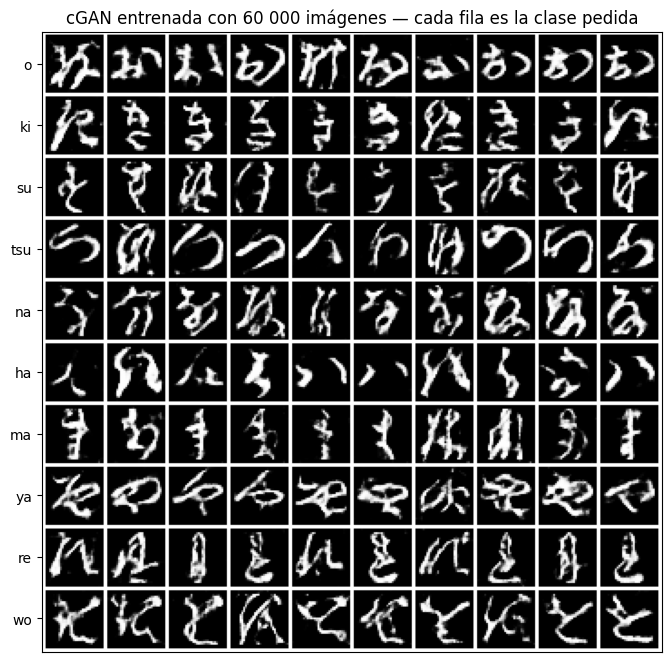

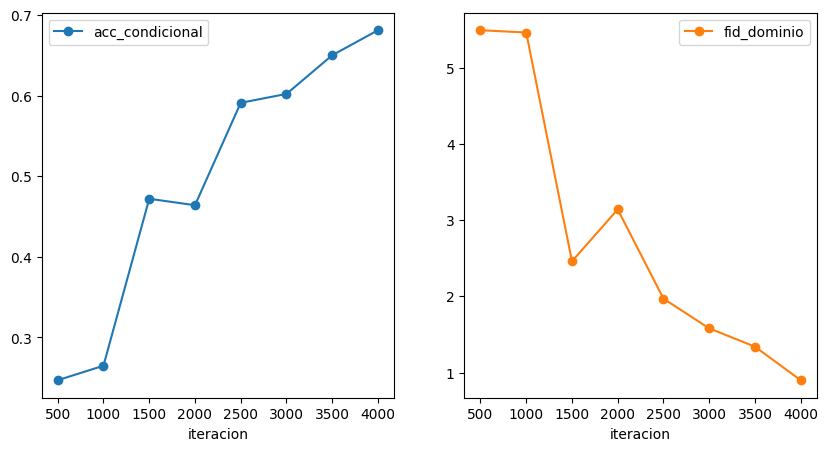

In [10]:
def rejilla_por_clase(G, titulo, nz=100):
    x, _ = muestras_cond(G, n_por_clase=10, nz=nz, semilla=7)
    g = make_grid(x.cpu(), nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(8, 8.4)); plt.imshow(g.permute(1, 2, 0)); plt.title(titulo)
    plt.yticks([17 + 34 * i for i in range(N_CLASES)], CLASES); plt.xticks([]); plt.show()

rejilla_por_clase(G_completo, "cGAN entrenada con 60 000 imágenes — cada fila es la clase pedida")
h_completo.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 5), layout=(1, 2)); plt.show()

Inspección visual ¿todas las filas corresponden a la clase pedida? ¿Hay diversidad de cada fila (colores, formas, poses) o se repite la misma prenda?

Solo 4 de las 10 filas son reconocidas por el juez como la clase pedida, y las clases ki, su, na, ha, ma y re quedan dudosas. La diversidad de cada fila es casi igual a la de las imágenes reales, con una razón media de 0.96, así que no se observa colapso de modos.

In [11]:
# Medición para la inspección visual de la Parte A: se cuantifica lo que se ve en la rejilla
@torch.no_grad()
def diversidad_intra(x, n=200):
    """Distancia L2 media entre pares de imágenes de un mismo conjunto (más alta = más variedad)."""
    f = x[:n].flatten(1); m = len(f)
    return torch.cdist(f, f).sum().item() / (m * (m - 1))

x_gen, y_gen = muestras_cond(G_completo, 200, semilla=5)
pred_gen = juez.probabilidades(x_gen).argmax(1)
filas = []
for c in range(N_CLASES):
    xg = x_gen[y_gen == c]; xr = X_te[Y_te == c][:200]
    filas.append(dict(clase=CLASES[c], acierto_juez=(pred_gen[y_gen == c] == c).float().mean().item(),
                      diversidad_gen=diversidad_intra(xg), diversidad_real=diversidad_intra(xr)))
tab_div = pd.DataFrame(filas); tab_div["razon_div"] = tab_div.diversidad_gen / tab_div.diversidad_real
display(tab_div.round(3))

,clase,acierto_juez,diversidad_gen,diversidad_real,razon_div
0,o,0.995,23.779,24.921,0.954
1,ki,0.305,20.795,22.660,0.918
2,su,0.505,21.701,23.200,0.935
3,tsu,0.850,24.852,25.505,0.974
4,na,0.540,25.329,25.695,0.986
5,ha,0.460,23.210,22.993,1.009
6,ma,0.715,22.063,22.471,0.982
7,ya,0.850,23.562,26.167,0.900
8,re,0.615,23.774,23.429,1.015
9,wo,0.815,23.724,24.310,0.976


## Parte B

Dos preguntas distintas, dos métricas:
* **¿Genera lo que se le pide?** → *exactitud condicional*: el juez clasifica las muestras de la clase *c* y medimos cuántas reconoce como *c*.
* **¿Se parece a la distribución real de esa clase?** → **FID de dominio por clase**: 1000 generadas de la clase *c* vs. las 1000 reales de prueba de esa clase.

,clase,acc_condicional,fid_dominio
0,o,0.992,1.743
1,ki,0.265,2.264
2,su,0.462,2.014
3,tsu,0.871,3.554
4,na,0.544,2.062
5,ha,0.456,2.170
6,ma,0.744,0.888
7,ya,0.877,3.401
8,re,0.658,1.868
9,wo,0.856,2.012


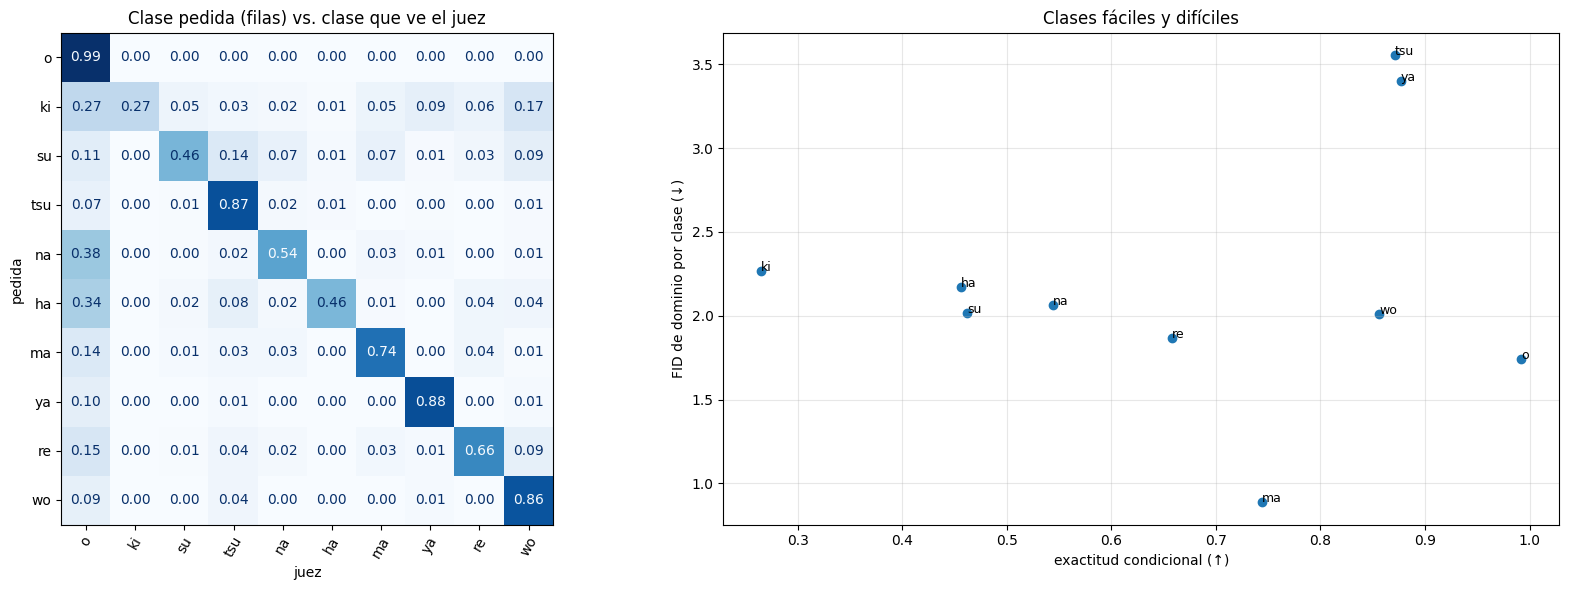

In [12]:
@torch.no_grad()
def evaluacion_por_clase(G, nz=100, n=1000):
    x, y = muestras_cond(G, n, nz, semilla=99)
    pred = juez.probabilidades(x).argmax(1)
    filas = []
    for c in range(N_CLASES):
        xc = x[y == c]; xr = X_te[Y_te == c][:n]
        filas.append(dict(clase=CLASES[c], acc_condicional=(pred[y == c] == c).float().mean().item(),
                          fid_dominio=fid_dominio(juez, xr, xc)))
    return pd.DataFrame(filas), y.cpu(), pred.cpu()

tabla_clase, y_ped, y_pred = evaluacion_por_clase(G_completo)
display(tabla_clase.round(3))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ConfusionMatrixDisplay(confusion_matrix(y_ped, y_pred, normalize="true"), display_labels=CLASES).plot(
    ax=ax[0], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set(title="Clase pedida (filas) vs. clase que ve el juez", xlabel="juez", ylabel="pedida"); ax[0].tick_params(axis="x", rotation=60)
ax[1].scatter(tabla_clase.acc_condicional, tabla_clase.fid_dominio)
for _, f in tabla_clase.iterrows(): ax[1].annotate(f.clase, (f.acc_condicional, f.fid_dominio), fontsize=9)
ax[1].set(xlabel="exactitud condicional (↑)", ylabel="FID de dominio por clase (↓)", title="Clases fáciles y difíciles"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("cgan_evaluacion_por_clase.png", dpi=110); plt.show()

¿Qué clases confunde más la cGAN? ¿Coinciden con las que confunde un clasificador normal (p. ej., camisa/camiseta/suéter/abrigo)? ¿Es un problema del generador, del juez, o de los datos?

La cGAN confunde sobre todo las clases ki, ha y su, y solo coincide en parte con el clasificador normal, ya que comparten 2 de los 4 pares más confundidos, na con o y ki con wo. En ki, su, na y ha el juez acierta más en reales que en generadas, así que ahí el culpable es el generador, y en los pares que también se confunden en reales la causa está en los datos de 28x28 y en el juez, una CNN pequeña de 3 épocas.

In [13]:
# Medición para la Parte B: ¿las confusiones de la cGAN son las mismas que las de un clasificador normal?
juez_pred_real = juez.probabilidades(X_te).argmax(1).cpu()
cm_real = confusion_matrix(Y_te.cpu(), juez_pred_real, normalize="true")
cm_gen = confusion_matrix(y_ped, y_pred, normalize="true")

def pares_confusion(cm, k=4):
    m = cm.copy(); np.fill_diagonal(m, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-m.ravel())[:k], m.shape))[0]
    return [(CLASES[i], CLASES[j], round(float(m[i, j]), 3)) for i, j in idx]

p_real, p_gen = pares_confusion(cm_real), pares_confusion(cm_gen)
print("Confusiones más grandes (clase real -> predicha) del juez sobre imágenes REALES:", p_real)
print("Confusiones más grandes (clase pedida -> predicha) del juez sobre imágenes GENERADAS:", p_gen)
comunes = {frozenset(p[:2]) for p in p_real} & {frozenset(p[:2]) for p in p_gen}
print("Pares de clases confundidas en ambos casos:", [tuple(sorted(c)) for c in comunes])

# si el juez acierta una clase real pero NO la generada, el problema es del generador
recall_real = np.diag(cm_real); acc_gen = tabla_clase.acc_condicional.values
brecha = pd.DataFrame({"clase": CLASES, "acierto_real": recall_real, "acierto_generada": acc_gen})
brecha["brecha"] = brecha.acierto_real - brecha.acierto_generada
display(brecha.round(3))

Confusiones más grandes (clase real -> predicha) del juez sobre imágenes REALES: [('na', 'o', 0.228), ('ki', 'wo', 0.162), ('re', 'o', 0.154), ('ya', 'o', 0.143)]
Confusiones más grandes (clase pedida -> predicha) del juez sobre imágenes GENERADAS: [('na', 'o', 0.379), ('ha', 'o', 0.335), ('ki', 'o', 0.265), ('ki', 'wo', 0.165)]
Pares de clases confundidas en ambos casos: [('na', 'o'), ('ki', 'wo')]


,clase,acierto_real,acierto_generada,brecha
0,o,0.989,0.992,-0.003
1,ki,0.517,0.265,0.252
2,su,0.696,0.462,0.234
3,tsu,0.932,0.871,0.061
4,na,0.697,0.544,0.153
5,ha,0.690,0.456,0.234
6,ma,0.822,0.744,0.078
7,ya,0.784,0.877,-0.093
8,re,0.790,0.658,0.132
9,wo,0.900,0.856,0.044


## Parte C

¿Ayudan los datos sintéticos cuando hay pocos reales?



**Escenario.** Solo tenemos `N_POR_CLASE` imágenes reales etiquetadas por clase. Comparamos:

| Clave | Datos de entrenamiento del clasificador | Protocolo |
|---|---|---|
| `R` | Solo las imágenes reales limitadas | TRTR (referencia) |
| `R+aum` | Reales limitadas + aumento clásico (desplazamiento ±2 px, espejo) | TRTR con aumento |
| `S_honesta` | Solo sintéticas de una cGAN entrenada **con las mismas imágenes limitadas** | TSTR |
| `R+S_honesta` | Reales limitadas + sintéticas honestas | TRSTR |
| `R+S_fuga` ⚠️ | Reales limitadas + sintéticas de la cGAN de la Parte A (vio **60 000** imágenes) | **No válido como resultado:** cota con fuga de información |
| `R_60k` | Las 60 000 reales | Techo de referencia |

Datos limitados: 500 imágenes reales (50 por clase)


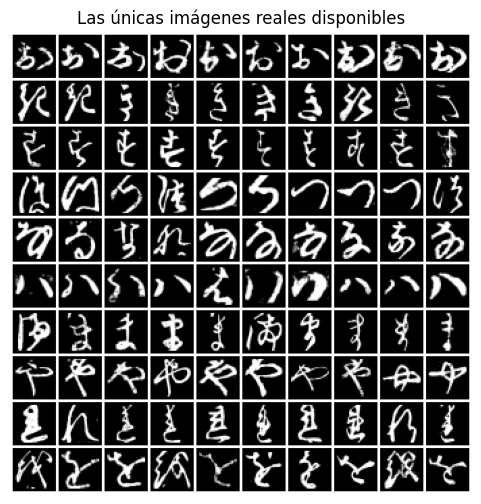

In [14]:
N_POR_CLASE = 50          # probar 20, 50 o 200
SINT_POR_CLASE = 500      # imágenes sintéticas por clase
PASOS_CLF = 800           # mismo presupuesto de entrenamiento para todos los clasificadores
SEMILLAS = [0, 1, 2]

def subconjunto_limitado(n, semilla=0):
    g = torch.Generator(device="cpu").manual_seed(semilla)
    idx = torch.cat([torch.nonzero(Y_tr.cpu() == c).view(-1)[torch.randperm(int((Y_tr == c).sum()), generator=g)[:n]]
                     for c in range(N_CLASES)])
    return X_tr[idx.to(DEVICE)], Y_tr[idx.to(DEVICE)]

def entrenar_clasificador(x, y, pasos=PASOS_CLF, batch=64, aumento=False, semilla=0):
    """Mismo clasificador para todas las condiciones; número de PASOS fijo (no de épocas)."""
    fijar_semilla(semilla)
    m = Juez(CANALES, N_CLASES).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    flujo = iter(()); batch = min(batch, len(x))
    for _ in range(pasos):
        try: xb, yb = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xb, yb = next(flujo)
        if aumento:
            xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
            if USAR_ESPEJO and np.random.rand() < 0.5: xb = xb.flip(3)
        m.train(); loss = F.cross_entropy(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    pred = m.probabilidades(X_te).argmax(1)
    return (pred == Y_te).float().mean().item(), pred

X_lim, Y_lim = subconjunto_limitado(N_POR_CLASE)
print(f"Datos limitados: {len(X_lim)} imágenes reales ({N_POR_CLASE} por clase)")
mostrar_grid(X_lim[torch.argsort(Y_lim)][:: max(1, N_POR_CLASE // 10)][:100], "Las únicas imágenes reales disponibles", tam=(6, 6))

### C.1 La cGAN2
Con tan pocos datos D puede **memorizar** el conjunto real y dejar de dar señal útil. Por eso activamos el aumento diferenciable y el ruido de instancia.

[cGAN-500] it   500/3000  loss_D 0.918  loss_G 1.625  acc_cond 0.495  FID-d 8.0  (13 s)
[cGAN-500] it  1000/3000  loss_D 1.275  loss_G 2.186  acc_cond 0.650  FID-d 6.5  (27 s)
[cGAN-500] it  1500/3000  loss_D 1.157  loss_G 0.837  acc_cond 0.258  FID-d 9.2  (40 s)
[cGAN-500] it  2000/3000  loss_D 0.942  loss_G 1.572  acc_cond 0.521  FID-d 7.6  (54 s)
[cGAN-500] it  2500/3000  loss_D 1.027  loss_G 1.972  acc_cond 0.504  FID-d 7.3  (67 s)
[cGAN-500] it  3000/3000  loss_D 1.086  loss_G 2.187  acc_cond 0.572  FID-d 7.8  (80 s)


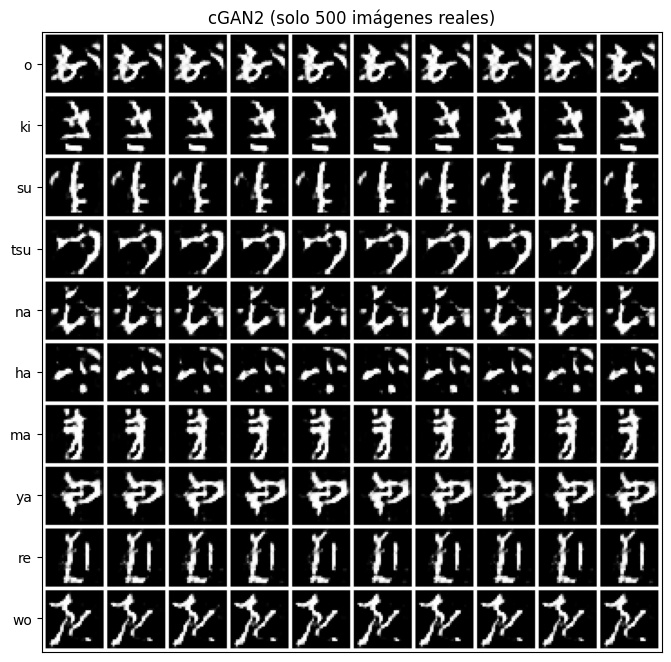

In [15]:
ITER_LIMITADO = 3000
G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.1, aumento_D=True,
                                     nombre=f"cGAN-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN2 (solo {len(X_lim)} imágenes reales)")

Entrena otra cGAN2 **sin** `aumento_D` ni ruido (`ruido_instancia=0.0, aumento_D=False`). Compara rejilla, exactitud condicional y FID. ¿Qué le pasa a D con 500 imágenes sin aumento?

Sin aumento ni ruido D rechaza casi todo lo generado, pues su salida sobre las falsas baja a 0.02 contra 0.44 con aumento mientras acepta lo real con 0.85, señal de que memoriza las 500 imágenes. Por eso la cGAN empeora, con FID de dominio de 12.9 contra 7.8 y exactitud condicional de 0.50 contra 0.57.

[cGAN-500-sin_aum] it   500/3000  loss_D 0.563  loss_G 3.238  acc_cond 0.190  FID-d 9.0  (13 s)
[cGAN-500-sin_aum] it  1000/3000  loss_D 0.501  loss_G 3.082  acc_cond 0.388  FID-d 9.5  (26 s)
[cGAN-500-sin_aum] it  1500/3000  loss_D 0.481  loss_G 5.289  acc_cond 0.200  FID-d 13.3  (40 s)
[cGAN-500-sin_aum] it  2000/3000  loss_D 0.434  loss_G 3.360  acc_cond 0.383  FID-d 16.7  (53 s)
[cGAN-500-sin_aum] it  2500/3000  loss_D 0.382  loss_G 4.207  acc_cond 0.480  FID-d 16.1  (66 s)
[cGAN-500-sin_aum] it  3000/3000  loss_D 0.385  loss_G 4.158  acc_cond 0.500  FID-d 12.9  (80 s)


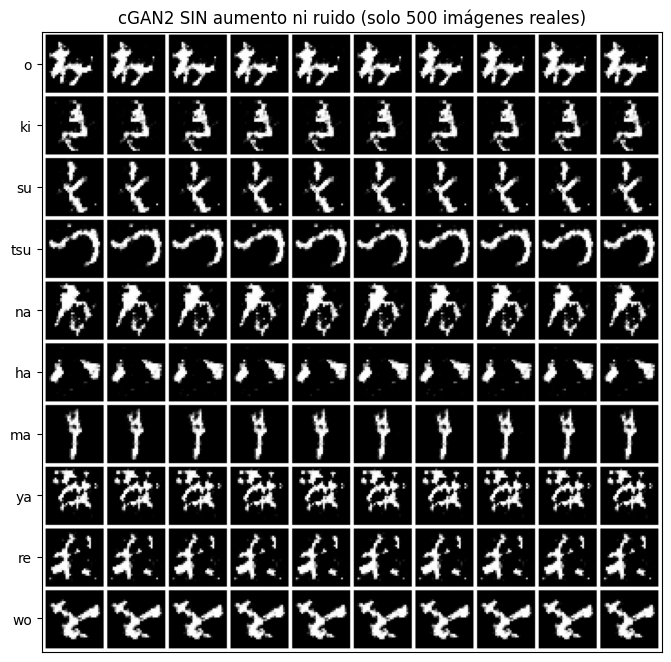

,loss_D,loss_G,D_x,D_Gz,acc_condicional,fid_dominio
con aumento + ruido,1.086,2.187,0.732,0.437,0.572,7.81
sin aumento ni ruido,0.385,4.158,0.847,0.021,0.500,12.91


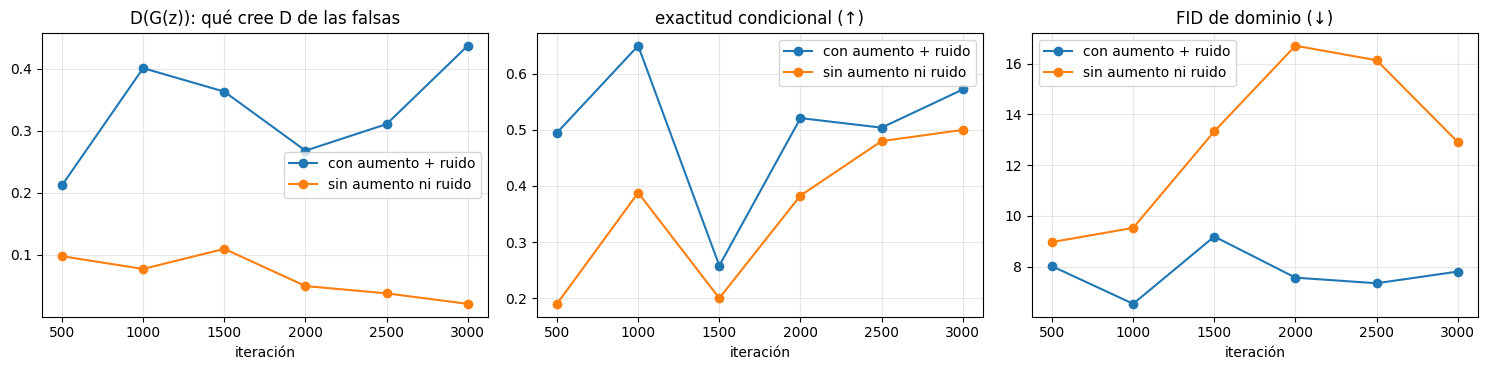

In [16]:
# TU TURNO C.1: la misma cGAN2 pero SIN aumento diferenciable y SIN ruido de instancia
G_sin, h_sin = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.0, aumento_D=False,
                             nombre=f"cGAN-{len(X_lim)}-sin_aum")
rejilla_por_clase(G_sin, f"cGAN2 SIN aumento ni ruido (solo {len(X_lim)} imágenes reales)")

comp = pd.DataFrame({"con aumento + ruido": h_honesta.iloc[-1], "sin aumento ni ruido": h_sin.iloc[-1]}).T
display(comp[["loss_D", "loss_G", "D_x", "D_Gz", "acc_condicional", "fid_dominio"]].astype(float).round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for h, etiqueta in [(h_honesta, "con aumento + ruido"), (h_sin, "sin aumento ni ruido")]:
    ax[0].plot(h.iteracion, h.D_Gz, marker="o", label=etiqueta)
    ax[1].plot(h.iteracion, h.acc_condicional, marker="o", label=etiqueta)
    ax[2].plot(h.iteracion, h.fid_dominio, marker="o", label=etiqueta)
for a, t in zip(ax, ["D(G(z)): qué cree D de las falsas", "exactitud condicional (↑)", "FID de dominio (↓)"]):
    a.set_title(t); a.set_xlabel("iteración"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

R              n=   500  exactitud = 0.554
R+aum          n=   500  exactitud = 0.625
S_honesta      n=  5000  exactitud = 0.241
R+S_honesta    n=  5500  exactitud = 0.449
R+S_fuga ⚠️    n=  5500  exactitud = 0.440
R_60k          n= 60000  exactitud = 0.594


,mean,std
condicion,,
R,0.5543,0.0062
R+aum,0.6249,0.0026
S_honesta,0.2405,0.0138
R+S_honesta,0.4492,0.0936
R+S_fuga ⚠️,0.4400,0.1116
R_60k,0.5945,0.0885


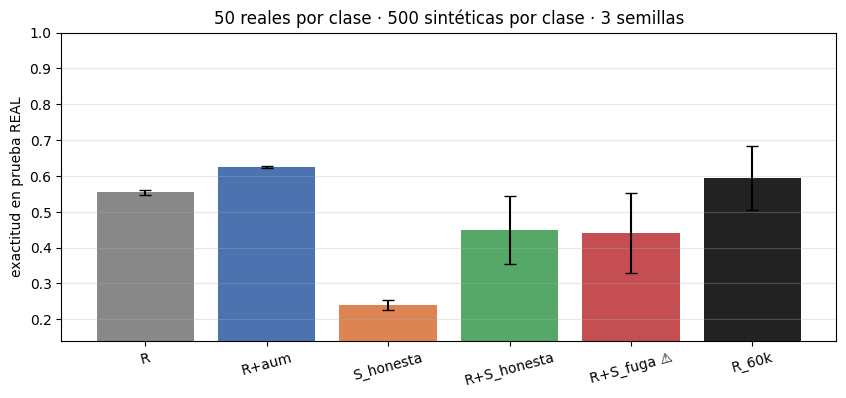

In [17]:
X_sh, Y_sh = muestras_cond(G_honesta, SINT_POR_CLASE, semilla=1)     # sintéticas honestas
X_sf, Y_sf = muestras_cond(G_completo, SINT_POR_CLASE, semilla=1)    # sintéticas con fuga

CONDICIONES = {
    "R":            lambda: (X_lim, Y_lim, False),
    "R+aum":        lambda: (X_lim, Y_lim, True),
    "S_honesta":    lambda: (X_sh, Y_sh, False),
    "R+S_honesta":  lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+S_fuga ⚠️":  lambda: (torch.cat([X_lim, X_sf]), torch.cat([Y_lim, Y_sf]), False),
    "R_60k":        lambda: (X_tr, Y_tr, False),
}
filas, preds = [], {}
for nombre, datos in CONDICIONES.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, pred = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas.append(dict(condicion=nombre, semilla=s, exactitud=acc, n_imagenes=len(x))); preds[(nombre, s)] = pred
    print(f"{nombre:<14s} n={len(x):>6}  exactitud = {np.mean([f['exactitud'] for f in filas if f['condicion'] == nombre]):.3f}")

res_aumento = pd.DataFrame(filas)
resumen_aum = res_aumento.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_aum)
res_aumento.to_csv(f"aumento_sintetico_N{N_POR_CLASE}.csv", index=False)

plt.figure(figsize=(10, 4))
colores = ["#888", "#4c72b0", "#dd8452", "#55a868", "#c44e52", "#222"]
plt.bar(resumen_aum.index, resumen_aum["mean"], yerr=resumen_aum["std"], capsize=4, color=colores)
plt.ylim(max(0, resumen_aum["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL")
plt.title(f"{N_POR_CLASE} reales por clase · {SINT_POR_CLASE} sintéticas por clase · {len(SEMILLAS)} semillas")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.savefig(f"aumento_sintetico_N{N_POR_CLASE}.png", dpi=110); plt.show()

In [18]:
# ¿En qué clases ayudaron (o dañaron) las sintéticas honestas? Diferencia de exactitud por clase vs. "R"
def acc_por_clase(nombre):
    return np.mean([[(preds[(nombre, s)][Y_te == c] == c).float().mean().item() for c in range(N_CLASES)] for s in SEMILLAS], axis=0)
dif = pd.DataFrame({"clase": CLASES,
                    "R": acc_por_clase("R"),
                    "Δ R+aum": acc_por_clase("R+aum") - acc_por_clase("R"),
                    "Δ R+S_honesta": acc_por_clase("R+S_honesta") - acc_por_clase("R")})
display(dif.round(3))

,clase,R,Δ R+aum,Δ R+S_honesta
0,o,0.453,0.141,0.174
1,ki,0.722,0.067,-0.272
2,su,0.523,-0.057,-0.182
3,tsu,0.540,0.085,0.096
4,na,0.474,-0.040,-0.258
5,ha,0.497,0.201,-0.171
6,ma,0.554,0.077,0.045
7,ya,0.612,-0.035,-0.231
8,re,0.689,-0.003,-0.142
9,wo,0.479,0.271,-0.110


Ordena las condiciones por exactitud. ¿Ayudó la cGAN honesta frente a `R`? ¿Y frente a `R+aum`? Responde con **media ± desviación** y discute si la diferencia es mayor que la variación entre semillas.

El orden por exactitud es R+aum 0.625 ± 0.003, R_60k 0.594 ± 0.088, R 0.554 ± 0.006, R+S_honesta 0.449 ± 0.094, R+S_fuga 0.440 ± 0.112 y S_honesta 0.241 ± 0.014. La cGAN honesta no ayudó, porque queda 0.105 abajo de R y 0.176 abajo de R+aum, diferencias mayores que la variación entre semillas, aunque con solo 3 semillas la evidencia es débil.

Explica con tus palabras por qué `R+S_fuga` **no** es un resultado válido aunque dé la mejor exactitud. ¿En qué situación real se cometería este error sin darse cuenta?

R+S_fuga no es válida porque sus sintéticas salen de la cGAN de la Parte A, que se entrenó con las 60 000 imágenes reales, así que el clasificador recibe información de datos que se suponía que no existían. El error pasa sin notarse cuando se entrena un generador, un preentrenamiento o un escalado con todo el dataset antes de separar entrenamiento y prueba.

¿Qué te dice `S_honesta` (TSTR) sobre la calidad de las sintéticas? ¿En qué clases la cGAN honesta ayudó o dañó más (tabla por clase)?

S_honesta obtiene 0.241 frente a 0.554 de R, lo que dice que la cGAN capturó poca información útil de cada clase y no reproduce bien la distribución real. Ayudó más en las clases o y tsu con 0.174 y 0.096, y dañó más en ki y na con -0.272 y -0.258, justo las clases que el juez ya confundía.

In [19]:
# Medición para la Parte C: orden, media ± desviación y comparación contra la variación entre semillas
tabla = res_aumento.groupby("condicion", sort=False).exactitud.agg(["mean", "std"])
print("Orden por exactitud media en prueba real:")
for nombre, f in tabla.sort_values("mean", ascending=False).iterrows():
    print(f"  {nombre:<14s} {f['mean']:.3f} ± {f['std']:.3f}")

print("\nTSTR (S_honesta) frente a las referencias:")
print(f"  S_honesta {tabla.loc['S_honesta','mean']:.3f} | R {tabla.loc['R','mean']:.3f} | R_60k {tabla.loc['R_60k','mean']:.3f}")

col_s = [c for c in dif.columns if c.endswith("R+S_honesta")][0]
mejor = dif.sort_values(col_s, ascending=False).head(2)
peor = dif.sort_values(col_s).head(2)
print("\nClases donde más ayudaron las sintéticas honestas:", [(r.clase, round(r[col_s], 3)) for _, r in mejor.iterrows()])
print("Clases donde más dañaron o menos ayudaron:", [(r.clase, round(r[col_s], 3)) for _, r in peor.iterrows()])

Orden por exactitud media en prueba real:
  R+aum          0.625 ± 0.003
  R_60k          0.594 ± 0.088
  R              0.554 ± 0.006
  R+S_honesta    0.449 ± 0.094
  R+S_fuga ⚠️    0.440 ± 0.112
  S_honesta      0.241 ± 0.014

TSTR (S_honesta) frente a las referencias:
  S_honesta 0.241 | R 0.554 | R_60k 0.594

Clases donde más ayudaron las sintéticas honestas: [('o', 0.174), ('tsu', 0.096)]
Clases donde más dañaron o menos ayudaron: [('ki', -0.272), ('na', -0.258)]


## Parte D

Prof asigna un equipo variación, la ejecuta (vuelve a correr la Parte C con el cambio) y la presenta en 2 minutos en clase + pregunta:

| Equipo | Variación | Pregunta |
|---|---|---|
| 1 | `N_POR_CLASE = 20` | ¿Con aún menos datos las sintéticas ayudan más o menos? |
| 2 | `N_POR_CLASE = 200` | ¿A partir de cuántos datos reales deja de valer la pena? |
| 3 | `SINT_POR_CLASE = 50` y `= 2000` | ¿Más sintéticas = mejor? ¿Hay saturación? |
| 4 | cGAN honesta sin aumento diferenciable | ¿Cuánto importa estabilizar la cGAN para que las sintéticas sirvan? |
| 5 | Combinar `R+aum` **y** sintéticas honestas | ¿Son complementarias las dos formas de aumento? |
| 6 | Filtrar sintéticas: conservar solo las que el juez clasifica con confianza > 0.9 en su clase | ¿Filtrar por calidad ayuda? (cuidado: ¿el juez vio datos que no debería?) |

El equipo asignado no se indica en el enunciado, así que se ejecuta la variación del equipo 5, que combina aumento clásico y sintéticas honestas, en la Parte E. Para otra variación basta cambiar N_POR_CLASE, SINT_POR_CLASE o los parámetros de entrenar_cgan y volver a correr la Parte C.

# Parte E
Ejecuta con tus datos reales, compara 1 variación y grafica 16 imagenes generas por cGAN y por Aumentación

En la variación 5 el aumento gana 0.035 sobre R, las sintéticas pierden 0.117 y combinarlas pierde 0.058, así que no son complementarias en esta corrida. En las 16 imágenes la diversidad es 4.4 para la cGAN, 21.2 para el aumento y 23.6 para las reales, por lo que el aumento conserva la clase con variedad parecida a la real y la cGAN muestra poca variedad.

,mean,std
condicion,,
R,0.5556,0.0093
R+aum,0.5911,0.0291
R+S_honesta,0.4385,0.0735
R+S_honesta+aum,0.4973,0.0305


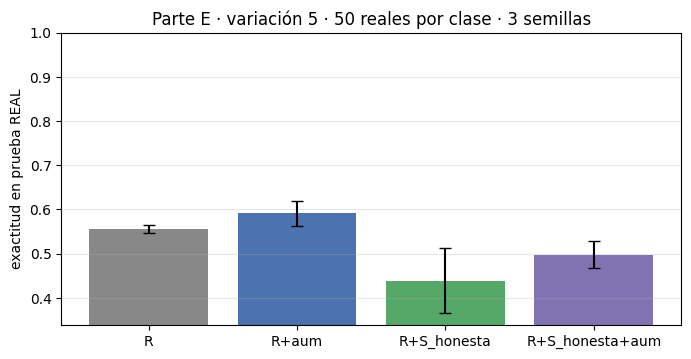

In [20]:
# Parte E · variación del equipo 5: ¿son complementarios el aumento clásico y las sintéticas honestas?
# Los datos reales son las N_POR_CLASE imágenes por clase de X_lim (para usar otro dataset basta cambiar DATASET arriba).
CONDICIONES_E = {
    "R":               lambda: (X_lim, Y_lim, False),
    "R+aum":           lambda: (X_lim, Y_lim, True),
    "R+S_honesta":     lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+S_honesta+aum": lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), True),
}
filas_e = []
for nombre, datos in CONDICIONES_E.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, _ = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas_e.append(dict(condicion=nombre, semilla=s, exactitud=acc))
res_e = pd.DataFrame(filas_e)
res_e.to_csv(f"parteE_variacion5_N{N_POR_CLASE}.csv", index=False)
resumen_e = res_e.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_e)

plt.figure(figsize=(8, 3.8))
plt.bar(resumen_e.index, resumen_e["mean"], yerr=resumen_e["std"], capsize=4, color=["#888", "#4c72b0", "#55a868", "#8172b2"])
plt.ylim(max(0, resumen_e["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL"); plt.grid(axis="y", alpha=.3)
plt.title(f"Parte E · variación 5 · {N_POR_CLASE} reales por clase · {len(SEMILLAS)} semillas")
plt.savefig(f"parteE_variacion5_N{N_POR_CLASE}.png", dpi=110); plt.show()

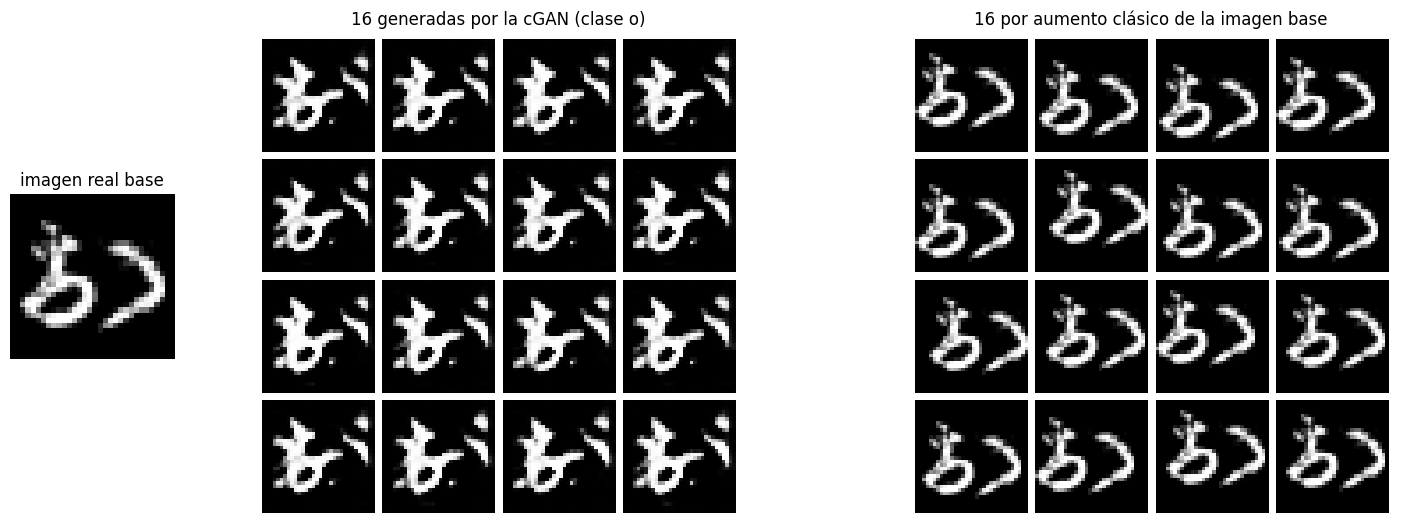

In [21]:
# Parte E · 16 imágenes generadas por la cGAN honesta vs. 16 generadas por aumento clásico (misma clase)
c_e = CLASES.index("tenis") if "tenis" in CLASES else 0      # cambia la clase si quieres ver otra

x_all, y_all = muestras_cond(G_honesta, 16, semilla=11)
x_cgan = x_all[y_all == c_e]                                   # (16, C, 32, 32) generadas por la cGAN

base = X_lim[Y_lim == c_e][:1]                                 # UNA imagen real de esa clase
rs = np.random.RandomState(11)
x_aug = torch.cat([torch.roll(base, shifts=(int(rs.randint(-2, 3)), int(rs.randint(-2, 3))), dims=(2, 3)) for _ in range(16)])
if USAR_ESPEJO:   # espejo al azar (solo si el dataset lo permite)
    x_aug = torch.where(torch.rand(16, 1, 1, 1, device=base.device) < 0.5, x_aug.flip(3), x_aug)

fig, ax = plt.subplots(1, 3, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 4, 4]})
ax[0].imshow(make_grid(base.cpu(), normalize=True, value_range=(-1, 1)).permute(1, 2, 0), cmap="gray")
ax[0].set_title("imagen real base"); ax[0].axis("off")
for a, x, t in [(ax[1], x_cgan, f"16 generadas por la cGAN (clase {CLASES[c_e]})"),
                (ax[2], x_aug, "16 por aumento clásico de la imagen base")]:
    g = make_grid(x.detach().cpu(), nrow=4, normalize=True, value_range=(-1, 1), pad_value=1)
    a.imshow(g.permute(1, 2, 0), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig("parteE_16_cgan_vs_aumento.png", dpi=110); plt.show()